In [ ]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
event_log = Path(r"..\dataset\raw\Event Log SCM.csv")   # Event Log; ID_Case, Activity, Timestamp

df = pd.read_csv(event_log, sep=";")    # Separate with ; 

print("Event log loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

In [ ]:
print(df.columns.tolist())
print(df.dtypes)

print(f"\nMissing Values: \n{df.isna().sum()}")
display(df.describe(include="all").T)

In [ ]:
df["TimeStamp"] = pd.to_datetime(
    df["TimeStamp"], 
    format="%d-%m-%Y %H:%M", 
    errors="coerce"
    )

print("Earliest timestamp:", df["TimeStamp"].min())
print("Latest timestamp:", df["TimeStamp"].max())
print("Invalid timestamps:", df["TimeStamp"].isna().sum())

display(df["TimeStamp"])

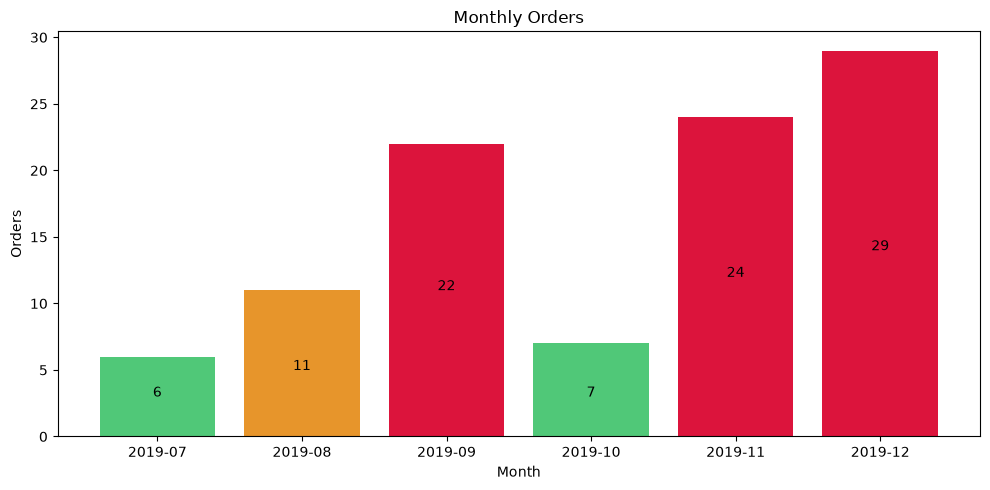

In [76]:
order_start = (
    df.groupby("ID_Case")["TimeStamp"]
      .min()
      .rename("OrderStart")
      .reset_index()
)

order_start["Month"] = order_start["OrderStart"].dt.to_period("M")

monthly_orders = (
    order_start.groupby("Month")["ID_Case"]
      .nunique()
      .rename("OrderCount")
      .reset_index()
)

# print(monthly_orders.to_string(index=False))

def add_labels(x, y):
    for i in range(len(x)):
        plt.text(i, y[i] // 2, y[i], ha='center')

x = monthly_orders["Month"].astype(str)
y = monthly_orders["OrderCount"]

colors = [
    '#50C878' if order <10 
    else "#E7952B" if order <20
    else 'crimson' 
    for order in y
    ]

plt.figure(figsize=(10, 5))
plt.bar(x, y, color=colors)
add_labels(x, y)
plt.title("Monthly Orders")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.tight_layout()
plt.show()

In [34]:
expected_activities = set(df["Activity"].unique())

activities_per_order = df.groupby("ID_Case")["Activity"].agg(set)

incomplete_orders = activities_per_order[
    activities_per_order.apply(lambda activities: len(activities) < 10)
]

for order_id, activities in incomplete_orders.items():
    missing = expected_activities - activities
    print(f"Order: {order_id}")
    print(f"  Recorded activities: {len(activities)}")
    print(f"  Missing activities: {sorted(missing)}")


Order: 190710123661H8U
  Recorded activities: 7
  Missing activities: ['Packet_to_Customer', 'Receiving warehouse', 'Shipping Warehouse']
Order: 190720055566T5G
  Recorded activities: 7
  Missing activities: ['Packet_to_Customer', 'Receiving warehouse', 'Shipping Warehouse']
Order: 19083116206CE3W
  Recorded activities: 8
  Missing activities: ['Packet_to_Customer', 'Shipping Warehouse']
Order: 19090109106NKEX
  Recorded activities: 7
  Missing activities: ['Packet_to_Customer', 'Receiving warehouse', 'Shipping Warehouse']
Order: 19091222006VXR5
  Recorded activities: 9
  Missing activities: ['Shipping Warehouse']
Order: 19091402406VPGV
  Recorded activities: 9
  Missing activities: ['Shipping Warehouse']
Order: 19100111236A2YH
  Recorded activities: 9
  Missing activities: ['Shipping Warehouse']
Order: 19100120286MNX1
  Recorded activities: 9
  Missing activities: ['Shipping Warehouse']
Order: 19111413076FUAN
  Recorded activities: 9
  Missing activities: ['Shipping Warehouse']
Order: